# Réplica: optimización multiobjetivo de la red Hanoi (NSGA-II y NSGA-III)

Réplica de Tao et al. (2022), *PLOS ONE* 17(11): e0277954, limitada a la red Hanoi con
NSGA-II y NSGA-III. Los datos están en `../data/` y las decisiones que el paper no
especifica, en `../docs/decisions.md`. Las salidas van a `../results/notebook/`.

Las corridas ya guardadas se saltan al reejecutar, así que si se cierra el kernel basta con
volver a correr todo. La sección (d) tarda unos 27 minutos la primera vez.

In [1]:
import json
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wntr
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.nsga3 import NSGA3
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.core.callback import Callback
from pymoo.core.problem import ElementwiseProblem
from pymoo.indicators.hv import HV
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.repair.rounding import RoundingRepair
from pymoo.operators.sampling.rnd import IntegerRandomSampling
from pymoo.optimize import minimize
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
from pymoo.util.ref_dirs import get_reference_directions
from scipy import stats
from scipy.spatial.distance import cdist

# Rutas relativas a la carpeta del notebook.
DATA = Path("../data")
OUT = Path("../results/notebook")
OUT.mkdir(parents=True, exist_ok=True)

# Parámetros (docs/decisions.md).
MIN_HEAD = 30.0             # cabeza mínima por nodo (m)
SANE_RANGE = (-1e5, 150.0)  # rango de cordura de presiones (m)
ALGORITHMS = ["nsga2", "nsga3"]
SEEDS = range(1, 31)
POP_SIZE, N_GEN = 100, 100
N_PARTITIONS = 12           # NSGA-III: Das-Dennis, 91 direcciones
HV_REF = 1.1

## (a) Red Hanoi y simulación

La red sale del archivo `.inp` de la Universidad de Exeter: 1 embalse a 100 m, 31 nodos de
consumo y 34 tuberías con Hazen-Williams C = 130. Los diámetros del archivo son marcadores
(0.0001); cada solución es un vector de 34 índices, de 0 a 5, al catálogo de diámetros.

In [2]:
def load_network():
    return wntr.network.WaterNetworkModel(str(DATA / "hanoi.inp"))


def load_catalog():
    """Diámetros (m) y costo ($/m) del catálogo, ordenados por id (índice 0 = id 1)."""
    catalog = pd.read_csv(DATA / "hanoi_diameters.csv").sort_values("id")
    return catalog["diameter_mm"].to_numpy(dtype=float) / 1000.0, catalog["cost_usd_per_m"].to_numpy(dtype=float)


PIPE_IDS = [str(i) for i in range(1, 35)]
DIAMETERS_M, UNIT_COSTS = load_catalog()


def assign_diameters(wn, x):
    for pipe_id, k in zip(PIPE_IDS, x):
        wn.get_link(pipe_id).diameter = float(DIAMETERS_M[k])


def simulate_pressures(wn):
    """Simulación por demanda con EPANET; presión (m) de todos los nodos."""
    with tempfile.TemporaryDirectory() as tmp:
        results = wntr.sim.EpanetSimulator(wn).run_sim(file_prefix=str(Path(tmp) / "sim"))
    return results.node["pressure"].iloc[0]


def pressures_are_sane(pressures):
    """EPANET no avisa con diámetros degenerados (da -1e35 m): esto detecta basura numérica."""
    p = np.asarray(pressures, dtype=float)
    return bool(p.size > 0 and np.all(np.isfinite(p)) and np.all((p >= SANE_RANGE[0]) & (p <= SANE_RANGE[1])))


WN = load_network()
JUNCTIONS = WN.junction_name_list
LENGTHS = np.array([WN.get_link(pipe_id).length for pipe_id in PIPE_IDS], dtype=float)
assert (WN.num_junctions, WN.num_reservoirs, WN.num_pipes) == (31, 1, 34)
assert np.isclose(LENGTHS.sum(), 39_420)
print("Catálogo (mm):", (DIAMETERS_M * 1000).round(1).tolist())
print("Con los diámetros de relleno, ¿pasa la cordura?", pressures_are_sane(simulate_pressures(load_network())))

Catálogo (mm): [304.8, 406.4, 508.0, 609.6, 762.0, 1016.0]


Con los diámetros de relleno, ¿pasa la cordura? False


## (b) Costo, f2, f3 y restricción de presión

- f1 = Σ C(Dᵢ) Lᵢ.
- f2 = Σ ΔSHᵢ, con ΔSHᵢ = pᵢ − 30 m en los 31 nodos de consumo, sin recortar negativos.
- f3 = varianza poblacional de ΔSHᵢ (m²).
- Restricción: G = Σ max(0, 30 − pᵢ); la solución es factible si G ≤ 0.
- Si la simulación no pasa la cordura, se devuelven valores finitos peores que cualquier
  solución real.

In [3]:
PENALTY = (1e8, 1e4, 1e10, 1e7)  # costo, f2, f3, G


def total_cost(x):
    return float(np.sum(UNIT_COSTS[np.asarray(x, dtype=int)] * LENGTHS))


def evaluate(wn, x):
    """(costo, f2, f3, G) de un vector de 34 índices; modifica wn en memoria."""
    x = np.round(x).astype(int)
    assign_diameters(wn, x)
    try:
        pressures = simulate_pressures(wn)
    except Exception:
        return PENALTY
    if not pressures_are_sane(pressures):
        return PENALTY
    surplus = np.asarray(pressures[list(JUNCTIONS)], dtype=float) - MIN_HEAD
    violation = float(np.sum(np.maximum(-surplus, 0.0)))
    return total_cost(x), float(np.sum(surplus)), float(np.var(surplus, ddof=0)), violation


cost, f2, f3, g = evaluate(WN, [5] * 34)
p_min = simulate_pressures(WN)[JUNCTIONS].min()
print(f"Todo 1016 mm: costo {cost:,.2f}, f2 {f2:.2f} m, f3 {f3:.2f} m², G {g}, presión mínima {p_min:.2f} m")
assert np.isclose(cost, 10_969_797.6)
assert abs(p_min - 49.62) < 0.01 and g == 0.0
assert np.isclose(total_cost([0] * 34), 1_802_518.92)

Todo 1016 mm: costo 10,969,797.60, f2 746.06 m, f3 71.70 m², G 0.0, presión mínima 49.62 m


## (c) Validación mono-objetivo

Antes del multiobjetivo, un GA que minimiza solo el costo con la restricción de presión
debe acercarse a 6.081 M, el mínimo de la literatura (criterio: ±2 %). El procedimiento
escalonado de `decisions.md` pasó con la semilla 4 y 500 generaciones; aquí se repite esa
corrida, que tarda unos 2 minutos.

In [4]:
OPERATORS = dict(sampling=IntegerRandomSampling(),
                 crossover=SBX(vtype=float, repair=RoundingRepair()),
                 mutation=PM(vtype=float, repair=RoundingRepair()),
                 eliminate_duplicates=True)


class CostProblem(ElementwiseProblem):
    def __init__(self):
        self.wn = load_network()
        super().__init__(n_var=34, n_obj=1, n_ieq_constr=1, xl=0, xu=5, vtype=int)

    def _evaluate(self, x, out, *args, **kwargs):
        cost, _, _, violation = evaluate(self.wn, x)
        out["F"], out["G"] = [cost], [violation]


validation_file = OUT / "validation.csv"
if validation_file.exists():
    validation = pd.read_csv(validation_file)
else:
    t0 = time.perf_counter()
    res = minimize(CostProblem(), GA(pop_size=POP_SIZE, **OPERATORS), ("n_gen", 500), seed=4)
    best = res.X if res.X is not None else res.algorithm.opt[0].X  # res.X es None si no hay factibles
    x_best = np.round(best).astype(int)
    cost, _, _, violation = evaluate(WN, x_best)
    validation = pd.DataFrame([{"seed": 4, "n_gen": 500, "cost": cost, "violation": violation,
                                "min_pressure": simulate_pressures(WN)[JUNCTIONS].min(),
                                "x": " ".join(map(str, x_best)),
                                "elapsed_s": round(time.perf_counter() - t0, 1)}])
    validation.to_csv(validation_file, index=False)
v = validation.iloc[0]
print(f"Costo {v.cost:,.2f} ({(v.cost - 6.081e6) / 6.081e6:+.2%} sobre 6.081 M), "
      f"presión mínima {v.min_pressure:.3f} m")
assert v.violation == 0 and abs(v.cost - 6.081e6) / 6.081e6 <= 0.02

Costo 6,173,342.08 (+1.52% sobre 6.081 M), presión mínima 30.005 m


## (d) NSGA-II y NSGA-III

Se usan población 100, 100 generaciones y semillas 1 a 30, con los mismos operadores que en
(c). NSGA-III usa direcciones de Das-Dennis con 12 particiones (91 direcciones). Cada
corrida guarda su frente final (soluciones factibles no dominadas) y su historial; las
semillas ya guardadas se saltan. Se ejecuta en serie: unos 27 segundos por corrida.

In [5]:
class HanoiProblem(ElementwiseProblem):
    def __init__(self):
        self.wn = load_network()
        super().__init__(n_var=34, n_obj=3, n_ieq_constr=1, xl=0, xu=5, vtype=int)

    def _evaluate(self, x, out, *args, **kwargs):
        cost, f2, f3, violation = evaluate(self.wn, x)
        out["F"], out["G"] = [cost, f2, f3], [violation]


def make_algorithm(name):
    if name == "nsga2":
        return NSGA2(pop_size=POP_SIZE, **OPERATORS)
    ref_dirs = get_reference_directions("das-dennis", 3, n_partitions=N_PARTITIONS)
    return NSGA3(ref_dirs=ref_dirs, pop_size=POP_SIZE, **OPERATORS)


def feasible_front(F, cv):
    """Índices de las soluciones factibles no dominadas."""
    feasible = np.flatnonzero(cv.ravel() <= 0)
    if feasible.size == 0:
        return feasible
    return np.sort(feasible[NonDominatedSorting().do(F[feasible], only_non_dominated_front=True)])


class History(Callback):
    def __init__(self):
        super().__init__()
        self.rows = []

    def notify(self, algorithm):
        F, cv = algorithm.pop.get("F"), algorithm.pop.get("CV").ravel()
        feasible = cv <= 0
        self.rows.append({"generation": algorithm.n_gen, "n_evals": algorithm.evaluator.n_eval,
                          "n_feasible": int(feasible.sum()), "front_size": len(feasible_front(F, cv)),
                          "min_cv": float(cv.min()),
                          "best_feasible_cost": float(F[feasible, 0].min()) if feasible.any() else np.nan})


X_COLS = [f"x{i}" for i in PIPE_IDS]
F_COLS = ["cost", "surplus_sum", "surplus_variance"]


def run_one(algo, seed):
    history = History()
    res = minimize(HanoiProblem(), make_algorithm(algo), ("n_gen", N_GEN), seed=seed, callback=history)
    X, F, G, cv = (res.pop.get(k) for k in ("X", "F", "G", "CV"))
    front = pd.DataFrame(np.round(X).astype(int), columns=X_COLS)
    front[F_COLS] = F
    front["G"] = G.ravel()
    front = front.iloc[feasible_front(F, cv)]
    return front.assign(seed=seed), pd.DataFrame(history.rows).assign(seed=seed)


def append_csv(df, path):
    df.to_csv(path, mode="a", header=not path.exists(), index=False)


def run_all(algo):
    """Corre las semillas que faltan; el historial se escribe al final y marca la semilla como hecha."""
    fronts_file, history_file = OUT / f"fronts_{algo}.csv", OUT / f"history_{algo}.csv"
    done = set(pd.read_csv(history_file)["seed"]) if history_file.exists() else set()
    if fronts_file.exists():  # quita restos de una semilla interrumpida
        fronts = pd.read_csv(fronts_file)
        fronts[fronts["seed"].isin(done)].to_csv(fronts_file, index=False)
    for seed in SEEDS:
        if seed in done:
            continue
        t0 = time.perf_counter()
        front, history = run_one(algo, seed)
        append_csv(front, fronts_file)
        append_csv(history, history_file)
        print(f"{algo} semilla {seed:2d}: {len(front)} soluciones en el frente, {time.perf_counter() - t0:.1f} s")


t0 = time.perf_counter()
for algo in ALGORITHMS:
    run_all(algo)
print(f"Tiempo de esta ejecución: {(time.perf_counter() - t0) / 60:.1f} min")
FRONTS = {a: pd.read_csv(OUT / f"fronts_{a}.csv") for a in ALGORITHMS}
HISTORY = {a: pd.read_csv(OUT / f"history_{a}.csv") for a in ALGORITHMS}
for a in ALGORITHMS:
    assert sorted(FRONTS[a]["seed"].unique()) == list(SEEDS)
    print(a, "tamaño del frente:", FRONTS[a].groupby("seed").size().describe()[["min", "50%", "max"]].tolist())

nsga2 semilla  1: 100 soluciones en el frente, 25.6 s


nsga2 semilla  2: 100 soluciones en el frente, 25.5 s


nsga2 semilla  3: 100 soluciones en el frente, 25.6 s


nsga2 semilla  4: 100 soluciones en el frente, 25.5 s


nsga2 semilla  5: 100 soluciones en el frente, 25.4 s


...

nsga3 semilla 26: 100 soluciones en el frente, 26.0 s


nsga3 semilla 27: 100 soluciones en el frente, 26.3 s


nsga3 semilla 28: 100 soluciones en el frente, 25.3 s


nsga3 semilla 29: 100 soluciones en el frente, 25.3 s


nsga3 semilla 30: 100 soluciones en el frente, 25.2 s
Tiempo de esta ejecución: 25.8 min
nsga2 tamaño del frente: [100.0, 100.0, 100.0]
nsga3 tamaño del frente: [100.0, 100.0, 100.0]


## (e) Hypervolume, Spacing y pruebas estadísticas

- **Normalización:** los objetivos se llevan a [0, 1] con el mínimo y el máximo de los 60
  frentes juntos.
- **HV:** punto de referencia 1.1 en cada eje; mayor es mejor.
- **Spacing:** el de Schott (1995, ec. 1), s² de la distancia Manhattan al vecino más
  cercano; menor es mejor.
- **Pruebas:** suma de rangos (principal) y rangos con signo emparejando por semilla
  (sensibilidad), bilaterales, α = 0.05.
- **Sensibilidad declarada de antemano:** HV con referencia 1.5 y Spacing como desviación
  estándar.

In [6]:
def hypervolume(F_norm, ref=HV_REF):
    return float(HV(ref_point=np.full(F_norm.shape[1], ref), norm_ref_point=False)(F_norm))


def spacing(F_norm):
    D = cdist(F_norm, F_norm, metric="cityblock")
    np.fill_diagonal(D, np.inf)
    d = D.min(axis=1)
    return float(np.sum((d.mean() - d) ** 2) / (len(d) - 1))


all_F = pd.concat(FRONTS.values())[F_COLS].to_numpy()
LOWER, UPPER = all_F.min(axis=0), all_F.max(axis=0)
rows = []
for algo in ALGORITHMS:
    for seed, front in FRONTS[algo].groupby("seed"):
        F_norm = (front[F_COLS].to_numpy() - LOWER) / (UPPER - LOWER)
        s2 = spacing(F_norm)
        rows.append({"algorithm": algo, "seed": seed, "front_size": len(front), "hv": hypervolume(F_norm),
                     "spacing": s2, "hv_ref_1_5": hypervolume(F_norm, ref=1.5), "spacing_sd": s2 ** 0.5})
METRICS = pd.DataFrame(rows)
METRICS.to_csv(OUT / "metrics.csv", index=False)


def compare(metric, higher_is_better, analysis):
    a = METRICS[METRICS.algorithm == "nsga2"].sort_values("seed")[metric].to_numpy()
    b = METRICS[METRICS.algorithm == "nsga3"].sort_values("seed")[metric].to_numpy()
    nsga2_better = np.median(a) > np.median(b) if higher_is_better else np.median(a) < np.median(b)
    return {"analysis": analysis, "metric": metric, "median_nsga2": np.median(a), "median_nsga3": np.median(b),
            "p_ranksums": stats.ranksums(a, b).pvalue, "p_wilcoxon": stats.wilcoxon(a, b).pvalue,
            "better": "NSGA-II" if nsga2_better else "NSGA-III"}


TESTS = pd.DataFrame([compare("hv", True, "principal"), compare("spacing", False, "principal"),
                      compare("hv_ref_1_5", True, "sensibilidad"), compare("spacing_sd", False, "sensibilidad")])
TESTS.to_csv(OUT / "tests.csv", index=False)
display(METRICS.groupby("algorithm")[["hv", "spacing"]].agg(["mean", "std", "median", "min", "max"]).T)
display(TESTS)

algorithm          nsga2     nsga3
hv      mean    0.863396  0.845216
        std     0.042367  0.105649
        median  0.867495  0.867794
        min     0.770183  0.644257
        max     0.951862  0.976542
spacing mean    0.000948  0.000873
        std     0.000375  0.000414
        median  0.000888  0.000768
        min     0.000356  0.000452
        max     0.001707  0.002496

,analysis,metric,median_nsga2,median_nsga3,p_ranksums,p_wilcoxon,better
0,principal,hv,0.867495,0.867794,0.668106,0.967674,NSGA-III
1,principal,spacing,0.000888,0.000768,0.273934,0.280087,NSGA-III
2,sensibilidad,hv_ref_1_5,2.590955,2.558079,0.375044,0.205410,NSGA-II
3,sensibilidad,spacing_sd,0.029800,0.027711,0.273934,0.338742,NSGA-III


## (f) Figuras y comparación con el paper

Los valores del paper salen de `../docs/spec.md` §6. Su "promedio de cabeza excedente" se
compara con nuestra presión promedio (promedio de ΔSH + 30), según `decisions.md`. La
discusión de las diferencias está en `../docs/comparacion.md`.

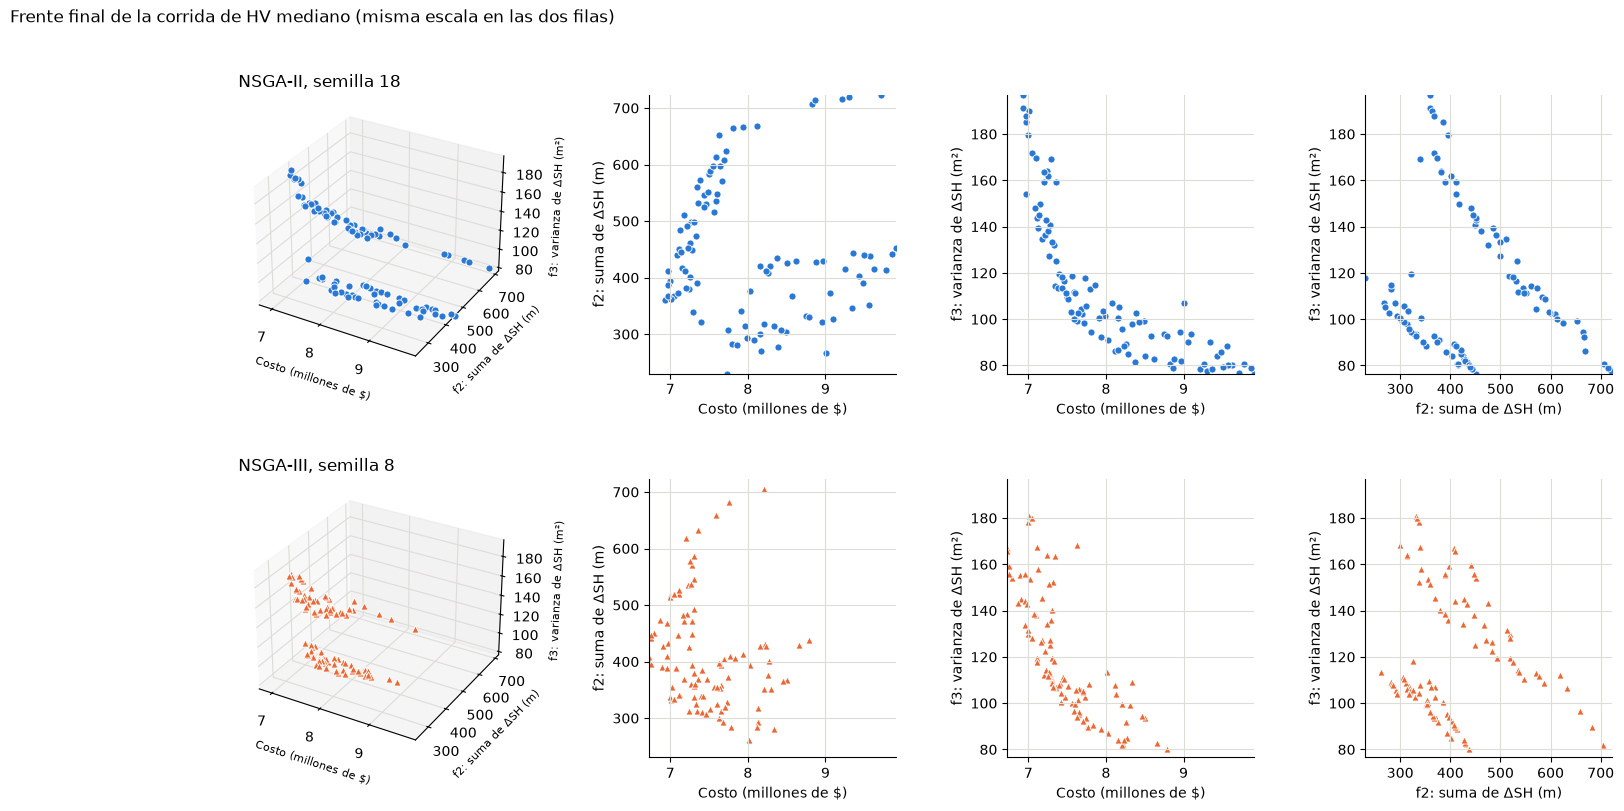

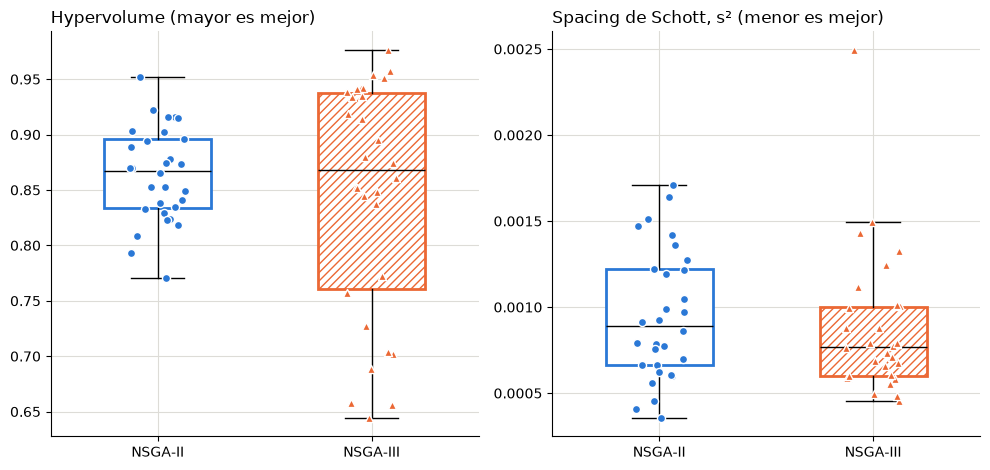

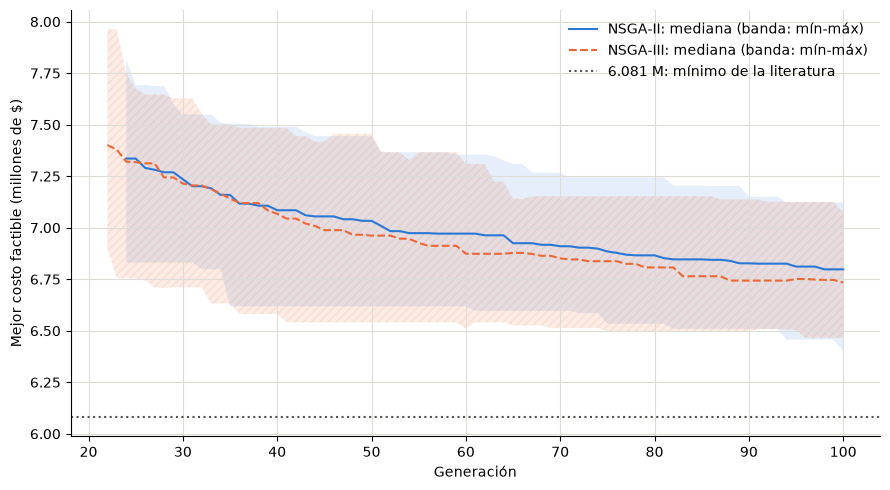

In [7]:
STYLE = {"nsga2": dict(label="NSGA-II", color="#2a78d6", marker="o", linestyle="-", hatch=""),
         "nsga3": dict(label="NSGA-III", color="#eb6834", marker="^", linestyle="--", hatch="////")}
LABELS = {"cost": "Costo (millones de $)", "surplus_sum": "f2: suma de ΔSH (m)",
          "surplus_variance": "f3: varianza de ΔSH (m²)"}
SCALE = {"cost": 1e-6, "surplus_sum": 1.0, "surplus_variance": 1.0}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#dddcd7", "legend.frameon": False})

# Frente de la corrida de HV mediano de cada algoritmo (misma escala para los dos).
median_seed = {a: int(METRICS[METRICS.algorithm == a].assign(d=lambda m: (m.hv - m.hv.median()).abs())
                      .sort_values(["d", "seed"]).iloc[0].seed) for a in ALGORITHMS}
fronts = {a: FRONTS[a][FRONTS[a].seed == median_seed[a]] for a in ALGORITHMS}
both = pd.concat(fronts.values())
lims = {c: (both[c].min() * SCALE[c], both[c].max() * SCALE[c]) for c in F_COLS}
fig = plt.figure(figsize=(18, 8.6))
grid = fig.add_gridspec(2, 4, width_ratios=[1.3, 1, 1, 1], wspace=0.42, hspace=0.38)
for row, algo in enumerate(ALGORITHMS):
    st, F = STYLE[algo], fronts[algo]
    marker = dict(color=st["color"], marker=st["marker"], s=26, edgecolors="white", linewidths=0.6)
    ax = fig.add_subplot(grid[row, 0], projection="3d")
    ax.scatter(*(F[c] * SCALE[c] for c in F_COLS), depthshade=False, **marker)
    ax.set(xlim=lims["cost"], ylim=lims["surplus_sum"], zlim=lims["surplus_variance"])
    ax.set_xlabel(LABELS["cost"], fontsize=8)
    ax.set_ylabel(LABELS["surplus_sum"], fontsize=8)
    ax.set_zlabel(LABELS["surplus_variance"], fontsize=8)
    ax.set_title(f"{st['label']}, semilla {median_seed[algo]}", loc="left")
    for k, (cx, cy) in enumerate([("cost", "surplus_sum"), ("cost", "surplus_variance"),
                                  ("surplus_sum", "surplus_variance")], start=1):
        ax2 = fig.add_subplot(grid[row, k])
        ax2.scatter(F[cx] * SCALE[cx], F[cy] * SCALE[cy], **marker)
        ax2.set(xlim=lims[cx], ylim=lims[cy], xlabel=LABELS[cx], ylabel=LABELS[cy])
fig.suptitle("Frente final de la corrida de HV mediano (misma escala en las dos filas)", x=0.01, ha="left")
fig.savefig(OUT / "fronts_median_hv.png", dpi=160, bbox_inches="tight")
plt.show()

# Diagramas de caja de HV y Spacing con las 30 corridas.
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, (metric, title) in zip(axes, [("hv", "Hypervolume (mayor es mejor)"),
                                      ("spacing", "Spacing de Schott, s² (menor es mejor)")]):
    data = [METRICS[METRICS.algorithm == a][metric].to_numpy() for a in ALGORITHMS]
    box = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False, medianprops=dict(color="black"))
    for i, (patch, algo) in enumerate(zip(box["boxes"], ALGORITHMS), start=1):
        st = STYLE[algo]
        patch.set(facecolor="white", edgecolor=st["color"], linewidth=2, hatch=st["hatch"])
        ax.scatter(i + rng.uniform(-0.13, 0.13, len(data[i - 1])), data[i - 1], color=st["color"], marker=st["marker"],
                   s=34, edgecolors="white", zorder=3)
    ax.set_xticks([1, 2], [STYLE[a]["label"] for a in ALGORITHMS])
    ax.set_title(title, loc="left")
fig.tight_layout()
fig.savefig(OUT / "metrics_boxplots.png", dpi=160)
plt.show()

# Mejor costo factible por generación: mediana y rango de las 30 corridas.
fig, ax = plt.subplots(figsize=(9, 5))
for algo in ALGORITHMS:
    st = STYLE[algo]
    wide = HISTORY[algo].pivot(index="generation", columns="seed", values="best_feasible_cost") * 1e-6
    wide = wide.loc[wide.notna().all(axis=1).idxmax():]  # desde que las 30 corridas tienen factibles
    ax.fill_between(wide.index, wide.min(axis=1), wide.max(axis=1), facecolor=st["color"], alpha=0.12,
                    hatch=st["hatch"], edgecolor=st["color"], linewidth=0)
    ax.plot(wide.index, wide.median(axis=1), color=st["color"], linestyle=st["linestyle"],
            label=f"{st['label']}: mediana (banda: mín-máx)")
ax.axhline(6.081, color="#52514e", linestyle=":", label="6.081 M: mínimo de la literatura")
ax.set(xlabel="Generación", ylabel="Mejor costo factible (millones de $)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "best_cost_evolution.png", dpi=160)
plt.show()

In [8]:
PAPER = {"nsga2": {"cost": 6_488_309.01, "mean_pressure": 36.05, "variance": 72.33},
         "nsga3": {"cost": 6_444_111.47, "mean_pressure": 36.16, "variance": 73.7}}
PAPER_P = {"hv": 7.9e-4, "spacing": 7.5e-4}  # Tabla 5, NSGA-II vs NSGA-III en Hanoi
PAPER_BETTER = {"hv": "NSGA-II", "spacing": "NSGA-III"}

rows = []
for algo in ALGORITHMS:
    F = FRONTS[algo]
    ours = {"cost": F["cost"], "mean_pressure": F["surplus_sum"] / 31 + MIN_HEAD, "variance": F["surplus_variance"]}
    for key, values in ours.items():
        run_minima = values.groupby(F["seed"]).min()
        paper = PAPER[algo][key]
        rows.append({"algorithm": STYLE[algo]["label"], "objective": key, "ours_min_union": values.min(),
                     "ours_median_of_run_minima": run_minima.median(), "paper": paper,
                     "rel_diff_union": (values.min() - paper) / paper,
                     "rel_diff_median_run": (run_minima.median() - paper) / paper})
COMPARISON = pd.DataFrame(rows)
COMPARISON.to_csv(OUT / "comparison.csv", index=False)
display(COMPARISON)
display(TESTS[TESTS.analysis == "principal"].assign(paper_p=lambda t: t.metric.map(PAPER_P),
                                                    paper_better=lambda t: t.metric.map(PAPER_BETTER)))

,algorithm,objective,ours_min_union,ours_median_of_run_minima,paper,rel_diff_union,rel_diff_median_run
0,NSGA-II,cost,6.401953e+06,6.798122e+06,6488309.01,-0.013309,0.047749
1,NSGA-II,mean_pressure,3.624446e+01,3.732771e+01,36.05,0.005394,0.035443
2,NSGA-II,variance,7.289801e+01,7.656417e+01,72.33,0.007853,0.058540
3,NSGA-III,cost,6.464775e+06,6.734126e+06,6444111.47,0.003207,0.045005
4,NSGA-III,mean_pressure,3.648252e+01,3.756735e+01,36.16,0.008919,0.038920
5,NSGA-III,variance,7.578438e+01,8.319564e+01,73.70,0.028282,0.128842


,analysis,metric,median_nsga2,median_nsga3,p_ranksums,p_wilcoxon,better,paper_p,paper_better
0,principal,hv,0.867495,0.867794,0.668106,0.967674,NSGA-III,0.00079,NSGA-II
1,principal,spacing,0.000888,0.000768,0.273934,0.280087,NSGA-III,0.00075,NSGA-III
